In [1]:
from typing import TypedDict, Annotated, List, Literal
from langgraph.graph import StateGraph, START, END 
import operator as op
from langgraph.types import interrupt, Command
from langgraph.checkpoint.memory import InMemorySaver

In [2]:
class State(TypedDict):
    try_count: int
    score: int
    messages: Annotated[List[str], op.add]
    

In [3]:
MAX_TRIES = 3

def start_flow(state: State):
    return {
        "messages": [f"Start function called with present try value of {state['try_count']}"],
        "try_count": state["try_count"] + 1,
        "score": state["score"] + 10
    }


def normal_flow(state):
    return {
            "messages": [f"It's a normal pass in try no. {state['try_count']}"],
        }


def human_flow(state):
    answer = interrupt({"question":"Tried so many times. Do you want to pass [YES/NO]"})
    verdict = "approved" if answer == "YES" else "not approved"
    return {"messages": [f"Manual verdict : {verdict}"]}

def judge(state)->Literal["normal_flow","start_flow","human_flow"]:
    if state["score"] >= 50:
        return "normal_flow"
    else:
        if state["try_count"] < MAX_TRIES:
            return "start_flow"
        else:
            return "human_flow"
    
    

In [4]:
def build_graph(checkpointer=None):
    builder = StateGraph(State)
    
    builder.add_node("start_flow", start_flow)
    builder.add_node("normal_flow", normal_flow)
    builder.add_node("human_flow", human_flow)
    
    builder.add_edge(START, "start_flow")      
    builder.add_conditional_edges("start_flow", judge)
    builder.add_edge("normal_flow", END)
    builder.add_edge("human_flow", END)  
    
    graph = builder.compile(checkpointer=checkpointer)
    
    return graph
    
    

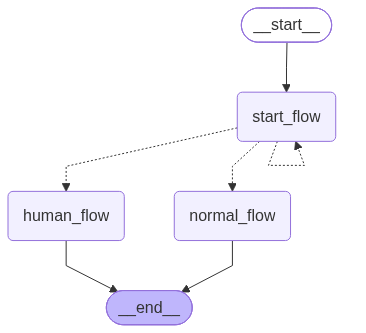

In [5]:
from IPython.display import Image, display

display(Image(build_graph().get_graph().draw_mermaid_png()))

In [6]:
graph = build_graph(InMemorySaver())

for pos,tup in enumerate([(0,10), (0,20), (0,30), (0,80)]):
    config = {
                "configurable": {
                        "thread_id":pos
                    }
                }
    res = graph.invoke({"try_count":tup[0], "score": tup[1], "messages":[]}, config = config)
    print(res)

{'try_count': 3, 'score': 40, 'messages': ['Start function called with present try value of 0', 'Start function called with present try value of 1', 'Start function called with present try value of 2'], '__interrupt__': [Interrupt(value={'question': 'Tried so many times. Do you want to pass [YES/NO]'}, id='7a4d8126e0baa05fff7858cfae597cde', response_schema=None)]}
{'try_count': 3, 'score': 50, 'messages': ['Start function called with present try value of 0', 'Start function called with present try value of 1', 'Start function called with present try value of 2', "It's a normal pass in try no. 3"]}
{'try_count': 2, 'score': 50, 'messages': ['Start function called with present try value of 0', 'Start function called with present try value of 1', "It's a normal pass in try no. 2"]}
{'try_count': 1, 'score': 90, 'messages': ['Start function called with present try value of 0', "It's a normal pass in try no. 1"]}


In [7]:
final = graph.invoke(Command(resume="YES"), {"configurable": {"thread_id":0}})
final

{'try_count': 3,
 'score': 40,
 'messages': ['Start function called with present try value of 0',
  'Start function called with present try value of 1',
  'Start function called with present try value of 2',
  'Manual verdict : approved']}

In [10]:
from langgraph.errors import GraphRecursionError

for pos,tup in enumerate([(0,10), (0,20), (0,30), (0,80)]):
    try:
        config = {
                    "configurable": {
                            "thread_id":pos+10
                        },
                    "recursion_limit": 3
                    }
        res = graph.invoke({"try_count":tup[0], "score": tup[1], "messages":[]}, config = config)
        print(res)
    except GraphRecursionError as e:
        print("unbounded:", type(e).__name__, "-", str(e).splitlines()[0])

unbounded: GraphRecursionError - Recursion limit of 3 reached without hitting a stop condition. You can increase the limit by setting the `recursion_limit` config key.
unbounded: GraphRecursionError - Recursion limit of 3 reached without hitting a stop condition. You can increase the limit by setting the `recursion_limit` config key.
unbounded: GraphRecursionError - Recursion limit of 3 reached without hitting a stop condition. You can increase the limit by setting the `recursion_limit` config key.
{'try_count': 1, 'score': 90, 'messages': ['Start function called with present try value of 0', "It's a normal pass in try no. 1", 'Start function called with present try value of 0', "It's a normal pass in try no. 1"]}


In [9]:

%%writefile test_bounded_loop.py
import copy
import uuid 

import pytest

@pytest.fixture
def graph():
    """A fresh graph with its own memory for every test."""
    build_graph(InMemorySaver())

@pytest.fixture
def config():
    """A fresh new config"""
    return {"configurable":{"thread_id":str(uuid.uuid4())}}

def run(graph, config, score):
    return graph.invoke({"score":score, "messages":[], "try_count": 0}, config)

def visited(graph, config, score):
    """Names of the nodes that ran, in order."""
    names = []
    for chunk in graph.stream({"score": score, "messages": [], "try_count":0}, config, stream_mode="updates"):
        names.extend(k for k in chunk if k != "__interrupt__")
    return names


def test_router_does_not_change_the_state():
    state = {"score": 120, "try_count":1, "messages": ["earlier"]}
    before = copy.deepcopy(state)
    judge(state)
    assert state == before


# ------------------------------------------------- 1. the router (no graph)

@pytest.mark.parameterize(
    "score, try_count, expected",
    [
        (10, 1, "start_flow"),
        (10, 4, "human_flow"),
        (50, 2, "normal_flow"),
        (60, 2, "normal_flow"),
    ],
)
def test_router_picks_the_right_branch(score, try_count, expected):
    assert judge({"score": score, "try_count": try_count, "messages": []}) == expected

# ------------------------------------------ 2. the whole graph, three paths
def test_small_score_is_auto_approved_without_pausing(graph, config):
    result = run(graph, config, 49)
    assert "__interrupt__" not in result
    assert result["messages"] == ["Start function called with present try value of 1", "It's a normal pass in try no. 1"]

def test_path_pauses_then_approves(graph, config):
    paused = run(graph, config, 10)
    assert "Tried so many times." in paused["__interrupt__"][0].value["question"]
    
    final = graph.invoke(Command(resume="YES"), config)
    assert final["messages"][-1] == "Manual verdict : approved"

def test_path_can_reject(graph, config):
    run(graph, config, 200)
    final = graph.invoke(Command(resume="no"), config)
    assert final["messages"][-1] == "Manual verdict : not approved"
    
def test_large_score_goes_to_the_director(graph, config):
    result = run(graph, config, 10)
    assert "__interrupt__" not in result
    assert result["messages"] == ["Start function called with present try value of 1", "It's a normal pass in try no. 1", "Start function called with present try value of 2","Start function called with present try value of 3"]


def test_path_taken_is_exactly_what_we_expect(graph, config):
    assert visited(graph, config, 59) == ["start_flow", "normal_flow"]
    
# ------------------------------------------------- 3. threads and memory
def test_different_threads_do_not_share_messagess(graph):
    a = {"configurable": {"thread_id": "A"}}
    b = {"configurable": {"thread_id": "B"}}
    run(graph, a, 49)
    result_b = run(graph, b, 49)
    assert result_b["messages"] == ["Start function called with present try value of 1", "It's a normal pass in try no. 1"]


def test_reusing_a_thread_keeps_the_old_messagess(graph, config):
    """Documents a behaviour that surprised us: the same thread_id continues the old state."""
    run(graph, config, 49)
    second = run(graph, config, 49)
    assert len(second["messages"]) == 4

Overwriting test_bounded_loop.py
